# Multimodal ASD classification — complete workflow (MMASD, Move4AS, Q-CHAT-10)

**Academic research prototype — not a clinically validated diagnostic system.**

This notebook drives the reproducible pipeline in `scripts/` and `src/`. Each step is a script so it can also be
run from a terminal (see `README.md`). Set `RUN_*` flags to `False` to only display existing outputs.

In [1]:
import subprocess, sys, json
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.utils.config import load_config
CONFIG = ROOT / "configs" / "default.yaml"      # SMOKE_TEST; use full_training.yaml for full runs
cfg = load_config(CONFIG)
PY = sys.executable
RUN_PREPARE, RUN_BUILD, RUN_TRAINING = False, False, False   # flip to True to recompute

def run(script, *args):
    print(">>", script, *args)
    r = subprocess.run([PY, str(ROOT / "scripts" / script), *args], cwd=ROOT, capture_output=True, text=True)
    print(r.stdout[-4000:]); print(r.stderr[-4000:])
    r.check_returncode()
print(cfg["run_label"], cfg["paths"]["project_root"])

SMOKE_TEST E:\ASD Project


## Steps 1-2 — dataset discovery, download verification, integrity checks & safe extraction

In [2]:
if RUN_PREPARE:
    run("download_move4as.py", "--verify-only")   # MD5 vs figshare API (needs network)
    run("prepare_datasets.py")                    # CRC test + safe extraction (idempotent)
pd.read_csv(cfg["paths"]["audit"] / "dataset_inventory.csv")

,dataset_hint,path,kind,size_bytes,n_members,uncompressed_bytes,zip_open,n_files
0,Move4AS (figshare bundle),E:\ASD Project\Dataset\28296518.zip,archive,5301146158,11.0,5.301144e+09,ok,NaN
1,Questionnaire (Kaggle Q-CHAT-10 toddlers),E:\ASD Project\Dataset\autism-screening-for-to...,archive,83665,3.0,3.316460e+05,ok,NaN
2,MMASD (Google Drive part),E:\ASD Project\Dataset\drive-download-20261023...,archive,1072029435,2.0,1.071865e+09,ok,NaN
3,MMASD (Google Drive part),E:\ASD Project\Dataset\drive-download-20261023...,archive,315520444,2.0,3.155075e+08,ok,NaN
4,MMASD (Google Drive part),E:\ASD Project\Dataset\drive-download-20261023...,archive,357010174,2.0,3.569553e+08,ok,NaN
5,MMASD extracted,E:\ASD Project\Dataset\MMASD,extracted_dir,3918396013,NaN,NaN,NaN,1187922.0
6,Move4AS extracted,E:\ASD Project\Dataset\Move4AS,extracted_dir,10281778114,NaN,NaN,NaN,697.0
7,MMASD optical flow (not used: no skeleton/EEG/...,E:\ASD Project\Dataset\optical_flow-001.zip,archive,5866669177,481176.0,6.465583e+09,ok,NaN
8,Questionnaire extracted,E:\ASD Project\Dataset\Questionnaire,extracted_dir,331646,NaN,NaN,NaN,3.0


## Steps 3-6 — preprocessing, alignment, audit

In [3]:
if RUN_BUILD:
    run("build_move4as.py", "--workers", "4")
    run("build_mmasd.py", "--workers", "4")
    run("audit_datasets.py")
display(Markdown((cfg["paths"]["audit"] / "dataset_comparison.md").read_text(encoding="utf-8")))

# Dataset comparison

| | Move4AS | MMASD | Q-CHAT-10 toddlers (Kaggle) |
|---|---|---|---|
| Population | adults (ASD 14, control 20) | children with ASD only (32) | toddlers 12-36 months (1054 rows) |
| ASD label | clinical group (folder P*/S*) | none (all ASD) | screening outcome = Q-CHAT sum > 3 |
| Valid binary ASD vs non-ASD task | **yes** | **no** | only as rule reproduction / demographics-only |
| Modalities | 3D mocap (21 rigid bodies), EEG (15/16 ch, 250 Hz), IMU | OpenPose 2D (25), ROMP 3D (24/71), optical flow, ADOS-2 | 10 binary items + demographics |
| Participant IDs | P1-P14, S1-S20 | 5-digit IDs | Case_No (row id) |
| Clinical scores | AQ (controls), ADOS (some ASD) | ADOS-2 for 20 participants with clips | none (screen score only) |
| Licence | CC BY 4.0 | research dataset (see repo) | Kaggle / original author terms |
| Key issues | small n; task-mix and 40-fps acquisition confounds | no controls; subject identity unlabelled in multi-person frames | target leakage by construction; Combined file mislabelled |

**Cross-dataset pairing:** none of the three datasets share participants, age group or label definition.
No multimodal fusion across datasets is performed; questionnaire fusion with Move4AS/MMASD is impossible
(would require questionnaires collected from the same Move4AS participants — e.g. the AQ, which exists only for
controls and therefore cannot be used).


In [4]:
m4 = json.loads((cfg["paths"]["audit"] / "move4as_audit.json").read_text())
print(json.dumps({k: m4[k] for k in ("participants", "alignment", "confounds_found")}, indent=1)[:4000])

{
 "participants": {
  "total": 34,
  "ASD": 14,
  "control": 20,
  "ids": [
   "P1",
   "P2",
   "P3",
   "P4",
   "P5",
   "P6",
   "P7",
   "P8",
   "P9",
   "P10",
   "P11",
   "P12",
   "P13",
   "P14",
   "S1",
   "S2",
   "S3",
   "S4",
   "S5",
   "S6",
   "S7",
   "S8",
   "S9",
   "S10",
   "S11",
   "S12",
   "S13",
   "S14",
   "S15",
   "S16",
   "S17",
   "S18",
   "S19",
   "S20"
  ]
 },
 "alignment": {
  "method": "per block: execution onsets (stim==4) in both modalities; offset s chosen so EEG trial k+s <-> motion trial k maximises cue agreement; accepted if >=95 % agreement over >=20 trials",
  "blocks_with_both": 155,
  "blocks_aligned": 147,
  "shift_counts": {
   "0.0": 109,
   "-1.0": 38
  },
  "unaligned_blocks": [
   "P2walk4",
   "S10dance9",
   "S11dance3",
   "S11walk1",
   "S19dance3",
   "S3walk3",
   "S5dance3",
   "S8dance4"
  ],
  "timestamp_note": "motion timestamps irregular (effective 50-60 Hz) -> resampled on time grid"
 },
 "confounds_found": [
  "t

In [5]:
mm = json.loads((cfg["paths"]["audit"] / "mmasd_audit.json").read_text())
print(mm["control_group"]); print(mm["subject_identity"]); print(mm["clinical_scores"]["n_overlap"], "participants with ADOS + clips")
q = json.loads((cfg["paths"]["audit"] / "questionnaire_audit.json").read_text())
print(q["target"])

NONE. All 32 participants are children with ASD; ADOS-2 classification column contains only ['1', '2'] (1 = ASD, 2 = autism). => No ASD-vs-non-ASD classification is performed on MMASD.
NOT annotated; primary tracked person heuristic (see src/data/mmasd.py)
20 participants with ADOS + clips
{'column': 'Class/ASD Traits', 'positive': 'Yes', 'counts': {'1': 728, '0': 326}, 'prevalence': 0.6907020872865275, 'type': 'screening outcome (ASDTests app), not clinical diagnosis', 'rule': 'Yes iff sum(A1..A10) > 3', 'rule_agreement': 1.0, 'score_column_equals_item_sum': True}


## Steps 7-11 — baselines, skeleton models, EEG, questionnaire, three fusion strategies (5-fold, SMOKE_TEST)

In [6]:
if RUN_TRAINING:
    run("run_questionnaire.py")
    run("run_move4as.py")
    run("run_move4as_sensitivity.py")
    run("run_mmasd.py")
    run("make_report.py")

## Step 12 — results

In [7]:
M = cfg["paths"]["metrics"]
cols = ["model", "roc_auc_mean", "roc_auc_std", "pooled_roc_auc", "pooled_roc_auc_ci95", "balanced_accuracy_mean", "mcc_mean"]
pd.read_csv(M / "A_move4as" / "summary_participant_level.csv")[cols].round(3)

,model,roc_auc_mean,roc_auc_std,pooled_roc_auc,pooled_roc_auc_ci95,balanced_accuracy_mean,mcc_mean
0,early_fusion_lr,0.967,0.075,0.966,"[0.9007169117647058, 1.0]",0.858,0.756
1,eeg_cnn,0.544,0.336,0.609,"[0.4190735901798736, 0.7963269054178145]",0.492,-0.025
2,eeg_feat_lr_all,0.667,0.250,0.621,"[0.4200749771062271, 0.8201208337322373]",0.600,0.225
3,eeg_feat_lr,0.628,0.256,0.602,"[0.3849130036630037, 0.7885808270676692]",0.675,0.373
4,intermediate_fusion,1.000,0.000,0.985,"[0.9421244530870199, 1.0]",0.933,0.894
5,late_fusion_deep,1.000,0.000,0.992,"[0.9661654135338346, 1.0]",0.942,0.891
6,late_fusion_lr,1.000,0.000,0.985,"[0.9444444444444444, 1.0]",0.892,0.823
7,motion_ctrgcn,1.000,0.000,0.992,"[0.9661654135338347, 1.0]",0.942,0.891
8,motion_feat_lr_all,1.000,0.000,0.992,"[0.9653571428571428, 1.0]",0.917,0.873
9,motion_feat_lr,1.000,0.000,0.985,"[0.9444444444444444, 1.0]",0.858,0.771


In [8]:
pd.read_csv(M / "A_move4as_sensitivity" / "summary_participant_level.csv")[["model","n","pooled_roc_auc","roc_auc_mean","balanced_accuracy_mean"]].round(3)

,model,n,pooled_roc_auc,roc_auc_mean,balanced_accuracy_mean
0,motion_feat_lr_reference,33,0.985,1.000,0.858
1,motion_feat_lr_task_balanced,33,0.981,1.000,0.858
2,motion_feat_lr_walk_only,24,1.000,1.000,0.750
3,eeg_feat_lr_walk_only,24,0.704,0.881,0.600
4,early_fusion_lr_walk_only,24,0.963,0.950,0.767
5,motion_feat_lr_dance_only,30,0.981,1.000,0.867
6,eeg_feat_lr_dance_only,30,0.611,0.628,0.650
7,early_fusion_lr_dance_only,30,0.921,0.872,0.817
8,motion_feat_lr_excl_40fps,29,0.990,1.000,0.917
9,eeg_feat_lr_excl_40fps,29,0.771,0.800,0.733


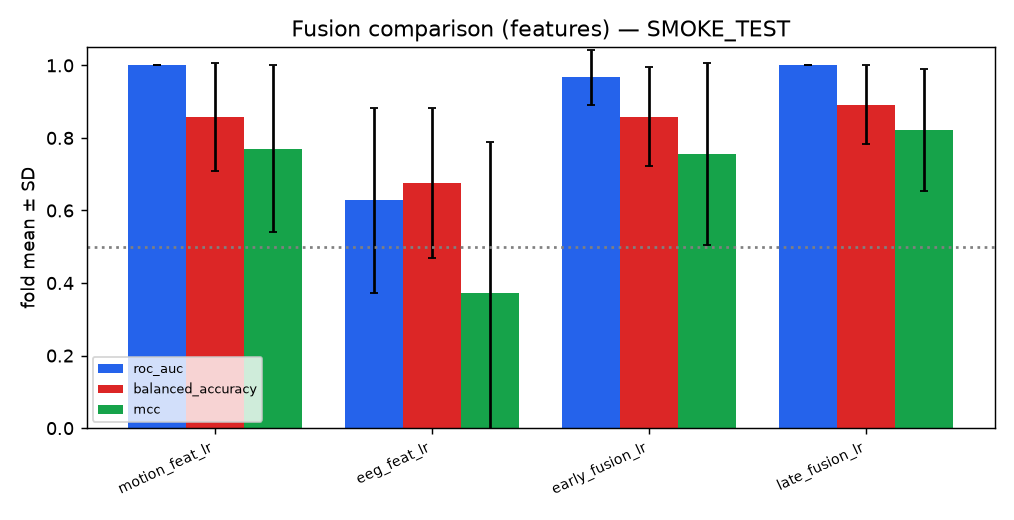

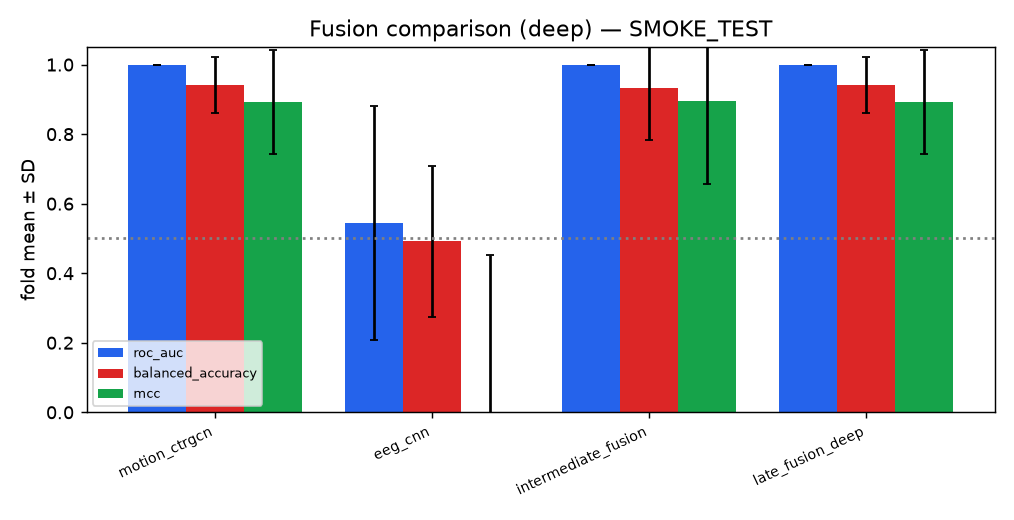

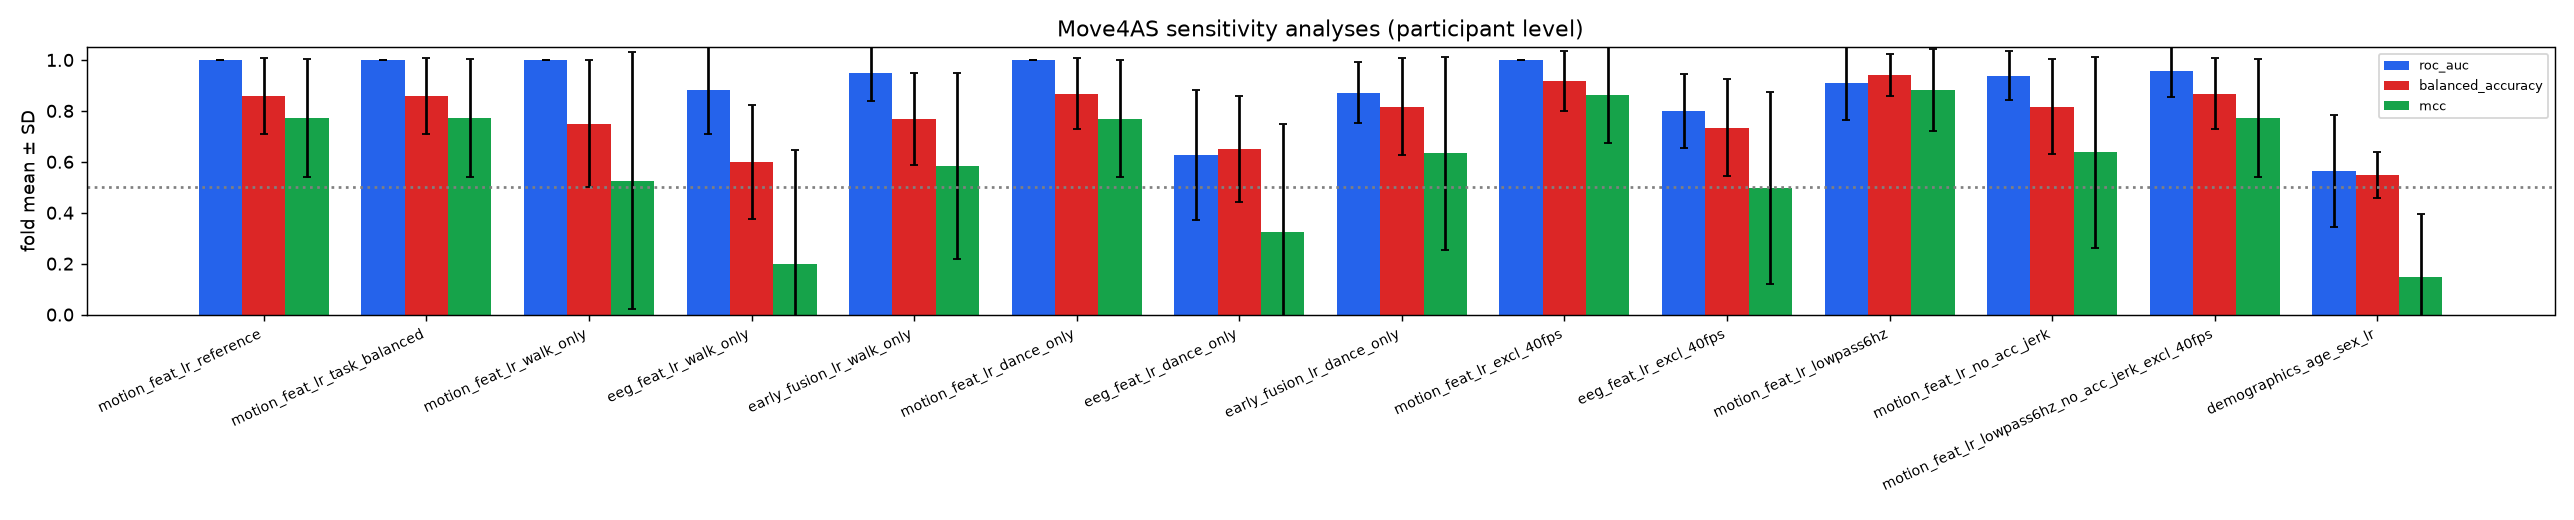

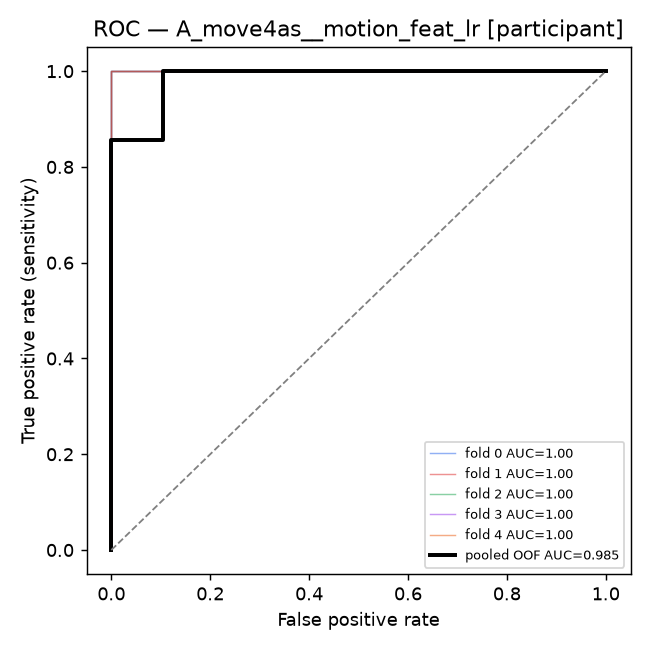

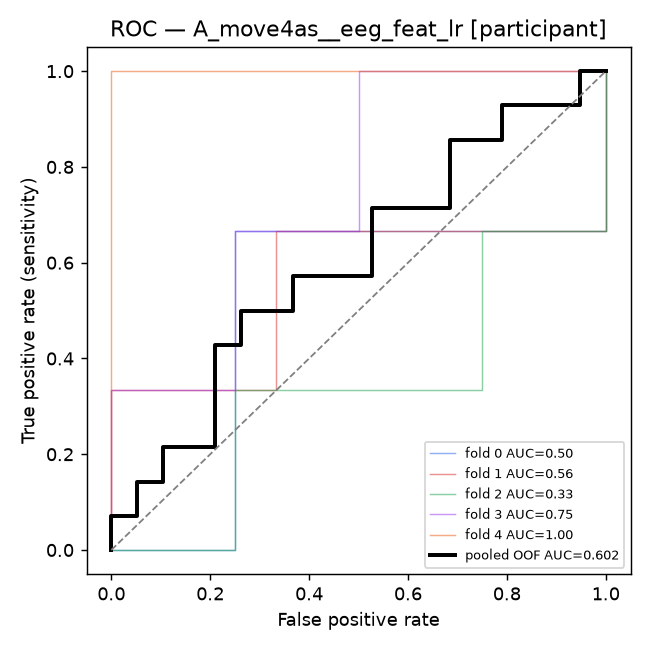

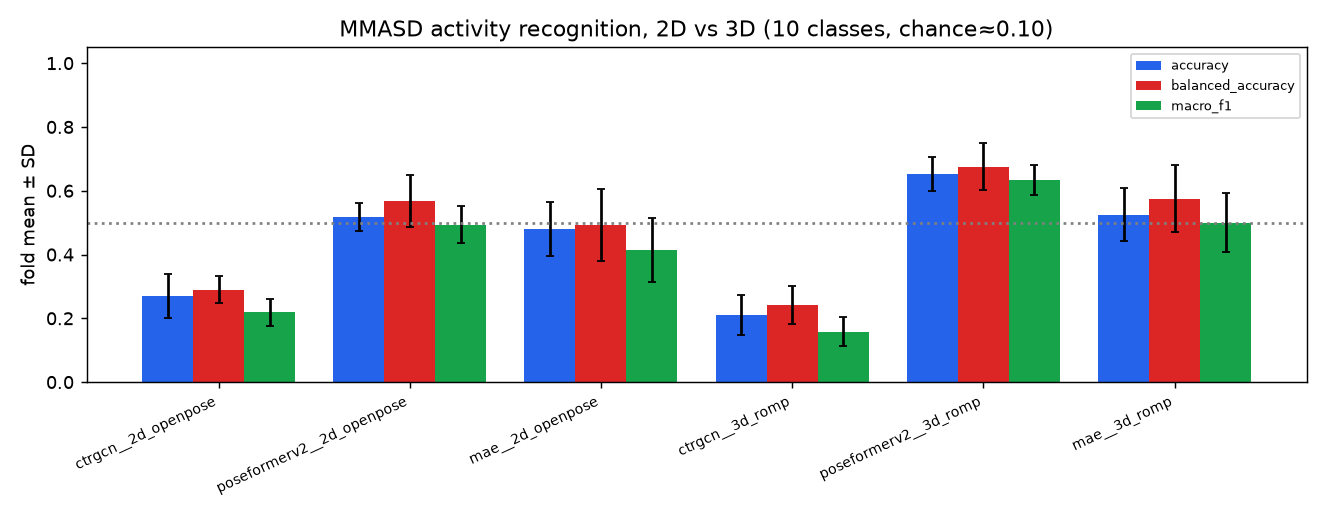

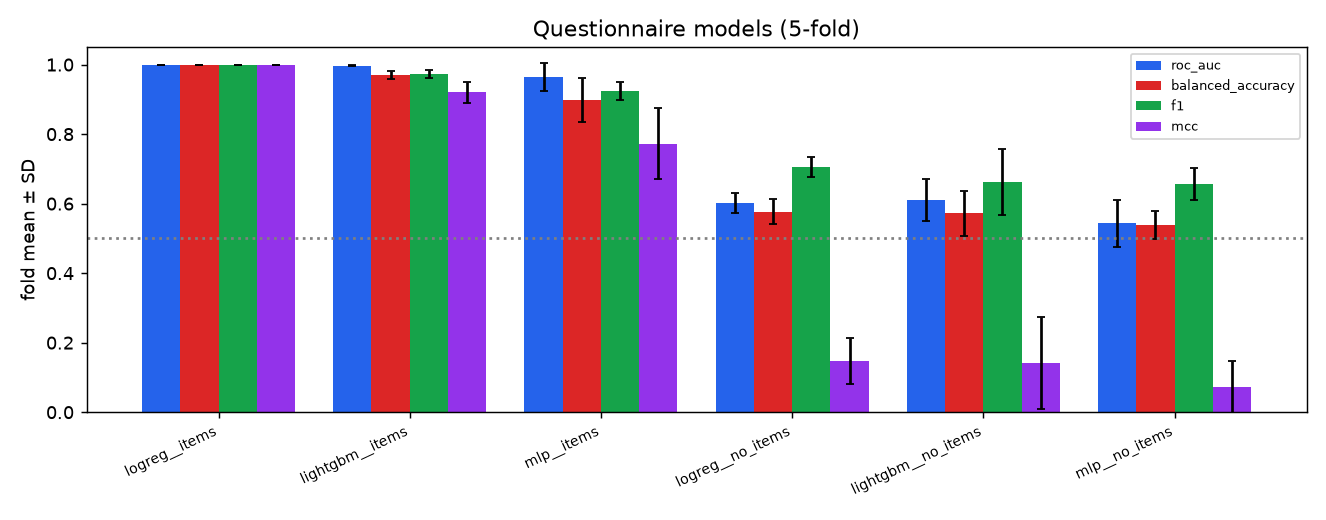

In [9]:
P = cfg["paths"]["plots"]
for f in ["comparisons/A_move4as_fusion_features.png", "comparisons/A_move4as_fusion_deep.png",
          "comparisons/A_move4as_sensitivity.png", "roc/A_move4as__motion_feat_lr_participant.png",
          "roc/A_move4as__eeg_feat_lr_participant.png", "comparisons/B_mmasd_activity.png",
          "comparisons/C_questionnaire_models.png"]:
    if (P / f).exists(): display(Image(filename=str(P / f), width=520))

In [10]:
pd.read_csv(M / "B_mmasd" / "b1_activity_summary.csv")[["model","pooled_accuracy","pooled_balanced_accuracy","pooled_macro_f1"]].round(3)

,model,pooled_accuracy,pooled_balanced_accuracy,pooled_macro_f1
0,ctrgcn__2d_openpose,0.269,0.279,0.256
1,poseformerv2__2d_openpose,0.517,0.556,0.533
2,mae__2d_openpose,0.480,0.479,0.458
3,ctrgcn__3d_romp,0.210,0.223,0.213
4,poseformerv2__3d_romp,0.652,0.671,0.663
5,mae__3d_romp,0.525,0.562,0.518


In [11]:
pd.read_csv(M / "B_mmasd" / "b3_ados_regression.csv")[["target","model","n_participants","mae","rmse","r2","spearman_rho"]].round(3)

,target,model,n_participants,mae,rmse,r2,spearman_rho
0,ados_comparison_score,ridge_kinematics,20,1.296,1.407,-0.125,-0.923
1,ados_comparison_score,mean_baseline,20,1.284,1.396,-0.108,-1.000
2,ados_overall_total,ridge_kinematics,20,9.867,12.428,-0.484,-0.491
3,ados_overall_total,mean_baseline,20,7.989,10.739,-0.108,-1.000


In [12]:
pd.read_csv(M / "C_questionnaire" / "summary.csv")[["model","roc_auc_mean","roc_auc_std","balanced_accuracy_mean"]].round(3)

,model,roc_auc_mean,roc_auc_std,balanced_accuracy_mean
0,logreg__items,1.000,0.000,1.000
1,lightgbm__items,0.997,0.001,0.970
2,mlp__items,0.964,0.041,0.898
3,logreg__no_items,0.601,0.029,0.577
4,lightgbm__no_items,0.611,0.060,0.572
5,mlp__no_items,0.543,0.067,0.538


## Step 13 — report
See `outputs/reports/final_report.md` (narrative, limitations, recommendations) and `outputs/reports/results_tables.md` (auto-generated tables).

In [13]:
display(Markdown((cfg["paths"]["reports"] / "results_tables.md").read_text(encoding="utf-8")[:6000]))

# Results tables (SMOKE_TEST)

Generated from `E:\ASD Project\outputs\metrics`. Mean ± SD over 5 participant-level folds; pooled = out-of-fold predictions of all participants (each fold's own training-selected threshold); 95 % CI = participant-level bootstrap (1,000 resamples).

## A. Move4AS — primary comparison (paired trials, participant level)

| model               |   n | roc_auc       | balanced_accuracy   | recall_sensitivity   | specificity   | f1            | mcc            | pooled AUC [95% CI]   |   pooled BA |   pooled Brier | TP/FP/TN/FN   |
|:--------------------|----:|:--------------|:--------------------|:---------------------|:--------------|:--------------|:---------------|:----------------------|------------:|---------------:|:--------------|
| motion_feat_lr      |  33 | 1.000 ± 0.000 | 0.858 ± 0.149       | 0.767 ± 0.325        | 0.950 ± 0.112 | 0.805 ± 0.218 | 0.771 ± 0.231  | 0.985 [0.944, 1.000]  |       0.867 |          0.07  | 11/1/18/3     |
| eeg_feat_lr         |  33 | 0.628 ± 0.256 | 0.675 ± 0.207       | 0.600 ± 0.279        | 0.750 ± 0.306 | 0.613 ± 0.236 | 0.373 ± 0.417  | 0.602 [0.385, 0.789]  |       0.654 |          0.276 | 8/5/14/6      |
| early_fusion_lr     |  33 | 0.967 ± 0.075 | 0.858 ± 0.137       | 0.767 ± 0.224        | 0.950 ± 0.112 | 0.827 ± 0.167 | 0.756 ± 0.250  | 0.966 [0.901, 1.000]  |       0.867 |          0.088 | 11/1/18/3     |
| late_fusion_lr      |  33 | 1.000 ± 0.000 | 0.892 ± 0.109       | 0.833 ± 0.236        | 0.950 ± 0.112 | 0.865 ± 0.141 | 0.823 ± 0.168  | 0.985 [0.944, 1.000]  |       0.902 |          0.077 | 12/1/18/2     |
| motion_ctrgcn       |  33 | 1.000 ± 0.000 | 0.942 ± 0.081       | 0.933 ± 0.149        | 0.950 ± 0.112 | 0.931 ± 0.096 | 0.891 ± 0.149  | 0.992 [0.966, 1.000]  |       0.938 |          0.053 | 13/1/18/1     |
| eeg_cnn             |  33 | 0.544 ± 0.336 | 0.492 ± 0.217       | 0.333 ± 0.471        | 0.650 ± 0.418 | 0.350 ± 0.412 | -0.025 ± 0.476 | 0.609 [0.419, 0.796]  |       0.494 |          0.245 | 5/7/12/9      |
| intermediate_fusion |  33 | 1.000 ± 0.000 | 0.933 ± 0.149       | 0.867 ± 0.298        | 1.000 ± 0.000 | 0.900 ± 0.224 | 0.894 ± 0.236  | 0.985 [0.942, 1.000]  |       0.929 |          0.092 | 12/0/19/2     |
| late_fusion_deep    |  33 | 1.000 ± 0.000 | 0.942 ± 0.081       | 0.933 ± 0.149        | 0.950 ± 0.112 | 0.931 ± 0.096 | 0.891 ± 0.149  | 0.992 [0.966, 1.000]  |       0.938 |          0.057 | 13/1/18/1     |
| motion_poseformerv2 |  33 | 0.983 ± 0.037 | 0.917 ± 0.078       | 0.933 ± 0.149        | 0.900 ± 0.137 | 0.891 ± 0.102 | 0.837 ± 0.149  | 0.966 [0.885, 1.000]  |       0.912 |          0.073 | 13/2/17/1     |
| motion_mae          |  33 | 0.967 ± 0.075 | 0.933 ± 0.149       | 0.867 ± 0.298        | 1.000 ± 0.000 | 0.900 ± 0.224 | 0.894 ± 0.236  | 0.977 [0.919, 1.000]  |       0.929 |          0.044 | 12/0/19/2     |
| motion_feat_lr_all  |  33 | 1.000 ± 0.000 | 0.917 ± 0.118       | 0.833 ± 0.236        | 1.000 ± 0.000 | 0.893 ± 0.153 | 0.873 ± 0.178  | 0.992 [0.965, 1.000]  |       0.929 |          0.067 | 12/0/19/2     |
| eeg_feat_lr_all     |  34 | 0.667 ± 0.250 | 0.600 ± 0.127       | 0.500 ± 0.289        | 0.700 ± 0.326 | 0.601 ± 0.081 | 0.225 ± 0.299  | 0.621 [0.420, 0.820]  |       0.6   |          0.255 | 7/6/14/7      |


### A. Trial level (secondary)

| model               |    n | roc_auc       | balanced_accuracy   | recall_sensitivity   | specificity   | f1            | mcc           | pooled AUC [95% CI]   |   pooled BA |   pooled Brier | TP/FP/TN/FN         |
|:--------------------|-----:|:--------------|:--------------------|:---------------------|:--------------|:--------------|:--------------|:----------------------|------------:|---------------:|:--------------------|
| motion_feat_lr      | 2709 | 0.876 ± 0.087 | 0.795 ± 0.102       | 0.756 ± 0.253        | 0.833 ± 0.102 | 0.739 ± 0.164 | 0.609 ± 0.183 | 0.895 [0.806, 0.960]  |       0.816 |          0.126 | 939/238/1281/251    |
| eeg_feat_lr         | 2709 | 0.602 ± 0.108 | 0.555 ± 0.101       | 0.513 ± 0.170        | 0.597 ± 0.230 | 0.494 ± 0.123 | 0.113 ± 0.205 | 0.590 [0.412, 0.736]  |       0.552 |          0.317 | 626/641/878/564     |
| early_fusion_lr     | 2709 | 0.846 ± 0.115 | 0.780 ± 0.107       | 0.770 ± 0.144        | 0.791 ± 0.084 | 0.742 ± 0.144 | 0.559 ± 0.218 | 0.869 [0.767, 0.937]  |       0.79  |          0.15  | 951/332/1187/239    |
| late_fusion_lr      | 2709 | 0.875 ± 0.096 | 0.798 ± 0.097       | 0.773 ± 0.236        | 0.822 ± 0.099 | 0.746 ± 0.152 | 0.610 ± 0.181 | 0.897 [0.802, 0.963]  |       0.818 |          0.124 | 957/256/1263/233    |
| motion_ctrgcn       | 2709 | 0.944 ± 0.032 | 0.862 ± 0.052       | 0.911 ± 0.108        | 0.812 ± 0.125 | 0.829 ± 0.070 | 0.712 ± 0.100 | 0.932 [0.874, 0.974]  |       0.853 |          0.118 | 1065/286/1233/125   |
| eeg_cnn             | 2709 | 0.545 ± 0.224 | 0.508 ± 0.128       | 0.347 ± 0.388        | 0.670 ± 0.388 | 0.317 ± 0.228 | 0.066 ± 0.279 | 0.542 [0.329, 0.762]  |       0.522 |          0.248 | 476/540/979/714     |
| intermediate_fusion | 2709 | 0.957 ± 0.029 | 0.894 ± 0.052       | 0.895 ± 0.092        | 0.893 ± 0.033 | 0.868 ± 0.070 | 0.777 ± 0.099 | 0.949 [0.893, 0.983]  |       0.887 |          0.109 | 1052/166/1353/138   |
| late_fusion_deep    | 2709 | 0.948 ± 0.031 | 0.862 ± 0.052       | 0.911 ± 0.108        | 0.812 ± 0.125 | 0.829 ± 0.070 | 0.712 ± 0.100 | 0.915 [0.856, 0.960]  |       0.853 |          0.115 | 1065/286/1233/125   |
| motion_poseformerv2 | 2709 | 0.962 ± 0.058 | 0.892 ± 0.081       | 0.847 ± 0.137        | 0.936 ± 0.090 | 0.868 ± 0.102 | 0.796 ± 0.146 | 0.938 [0.861, 0.985]  |       0.892 |          0.098 | 1020/110/1409/170   |
| motion_mae          | 2709 | 0.968 ± 0.036 | 0.901 ± 0.080       | 0.842 ± 0.196        | 0.959 ± 0.042 | 0.878 ± 0.100 | 0.835 ± 0.111 | 0.956 [0.911, 0.987]  |       0.915 |          0.087 | 1029/53/1466/161    |
| motion_feat_lr_all  | 3388 | 0.887 ± 0.082 | 0.820 ± 0.